id: notebooks/07_deconvolution.ipynb

Högbom CLEAN, clean beam and restoration, Wiener filter; comparison with the true sky

<!-- notebooks/07_deconvolution.ipynb -- deconvolution (Interferosim 0.8.0) -->
# 07 – Deconvolution: from the dirty image to the sky

---
  DI Erich Schubert, 07925151
  


Notebook 06 ended with the dirty image: the sky convolved with the dirty beam. With a single baseline the beam has sidelobes of almost half its peak, and each source contaminates the others. Deconvolution removes the beam again. Two methods are compared: the non-linear **Högbom CLEAN**, which assumes a few point sources and thereby fills the unmeasured uv cells, and the linear **Wiener filter**, which can only re-weight what was measured.

Package: `interferosim.deconvolution` – `HogbomClean` and `WienerFilter` (both realise the interface `Deconvolver`), `CleanBeam`, `DeconvResult`, `WienerFilter`, `reference_image`, `rms_error`; plot `plot_clean_history`. Origin: notebook A of the teaching material (`hogbom_fft`, clean beam, comparison Wiener against CLEAN).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from interferosim.constants import OH_1665, HI_21CM
from interferosim.instrument import Antenna, Receiver, Site, Station, Array
from interferosim.sky import SkyModel
from interferosim.observation import Observation, VisibilitySimulator
from interferosim.imaging import Gridder, Imager, NaturalWeighting, UniformWeighting, WienerWeighting
from interferosim.deconvolution import CleanBeam, HogbomClean, WienerFilter, reference_image, rms_error
from interferosim.plotting import plot_image, plot_clean_history, sky_marks

CFG = Path("..") / "configs"
DATE = "2026-11-01"
site = Site.from_toml(CFG / "sites" / "wilhelmsburg.toml")
dish = Antenna.from_toml(CFG / "antennas" / "dish_3m.toml")
b210 = Receiver.from_toml(CFG / "receivers" / "b210.toml")
target = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                      Station.from_enu("X", site, 11_500, 0, 0, dish)], receiver=b210,
               name="project baseline 11.5 km east-west (model)")
three = Array(site, [Station.from_enu("W", site, 0, 0, 0, dish),
                     Station.from_enu("E", site, 11_500, 0, 0, dish),
                     Station.from_enu("N", site, 0, 6_000, 0, dish)], receiver=b210,
              name="hypothetical three-station array")
masers = SkyModel.from_json(CFG / "skies" / "w3oh_masers.json")
cyga = SkyModel.from_json(CFG / "skies" / "cyg_a.json")
M1 = (masers["Maser M1"].dx_deg, masers["Maser M1"].dy_deg)       # image centre for the masers
GRID = Gridder(512, 0.25)                                          # field 128", uv cell small enough for M3

def maser_images(array, weighting=None, seed=1):
    """Visibilities of the maser group (±8 h, 1-min integrations) -> dirty image and beam."""
    o = Observation.from_sky(masers, array, ha_range_h=(-8, 8), t_int_s=60, freq_hz=OH_1665, date=DATE)
    v = VisibilitySimulator(seed=seed).run(masers, o)
    return Imager(GRID, weighting or NaturalWeighting()).both(v, center_deg=M1)

def maser_offsets():
    return [(c.name, (c.dx_deg - M1[0]) * 3600, (c.dy_deg - M1[1]) * 3600) for c in masers]

def plot_components(res, ax, zoom, title="CLEAN components"):
    """CLEAN components as dots, area proportional to the flux."""
    comp = res.components()
    l, m, f = (np.array(x) for x in zip(*comp)) if comp else (np.zeros(0),) * 3
    ax.scatter(l, m, s=4 + 60 * np.abs(f) / max(np.abs(f).max(), 1e-9), c=np.where(f >= 0, "C1", "C0"))
    ax.set_xlim(zoom, -zoom); ax.set_ylim(-zoom, zoom); ax.set_aspect("equal")
    ax.set_xlabel(r"$\Delta\alpha$ (east)  [arcsec]"); ax.set_ylabel(r"$\Delta\delta$ (north)  [arcsec]")
    ax.set_title(f"{title}\n{len(comp)} pixels, {res.total_flux_jy:.1f} Jy", fontsize=10); ax.grid(alpha=0.3)

## 1. Principle

**Högbom CLEAN** (1974) assumes that the sky consists of a limited number of point sources:

1. find the peak of the residual image (initially the dirty image $I_D$);
2. subtract the dirty beam, shifted to the peak and scaled by the **loop gain** $g$ times the peak value; store $g\cdot$peak as a CLEAN component;
3. repeat until the peak falls below a threshold (a few times the noise) or after $n_\mathrm{iter}$ iterations;
4. **restore**: convolve the components with the **clean beam** $B_C$ – a Gaussian fitted to the main lobe of $B_D$ – and add the residual image:
$$I_R = M * B_C + R .$$

Because the component model $M$ has a Fourier transform defined everywhere, CLEAN implicitly fills the unmeasured uv cells – justified as long as the sky really is sparse.

The **Wiener filter** is linear: $\hat I = \mathcal W\,D$ with $\mathcal W = \mathcal S^*/(|\mathcal S|^2 + \Phi_n/\Phi_s)$ and the transfer function $\mathcal S$ = FFT of the dirty beam. Where $\mathcal S = 0$, $\mathcal W D = 0$: no linear filter fills an empty cell.

| | Wiener filter | CLEAN |
|---|---|---|
| type | linear | non-linear (greedy) |
| prior information | power spectrum of the sky | few point sources |
| unmeasured uv cells | stay empty | filled from the model |
| suitable for | filled aperture (dish) | sparse sampling (interferometer) |
| fails for | gaps in the sampling | extended emission |

**Reference ("truth").** The visibilities see the sky attenuated by the primary beam of the 3 m dishes (the masers lie 0.54° from the pointing centre W3(OH): factor ≈ 0.96). `reference_image(..., antenna=dish, freq_hz=...)` renders this apparent sky on the image grid and convolves it with the clean beam; `rms_error` compares within 30″.

## 2. CLEAN on the maser group with the project baseline

Natural weighting, grid 512 × 0.25″, loop gain 0.1, threshold 0.45 Jy/beam (3 × the noise of notebook 06), CLEAN only positive peaks (masers have no negative flux).

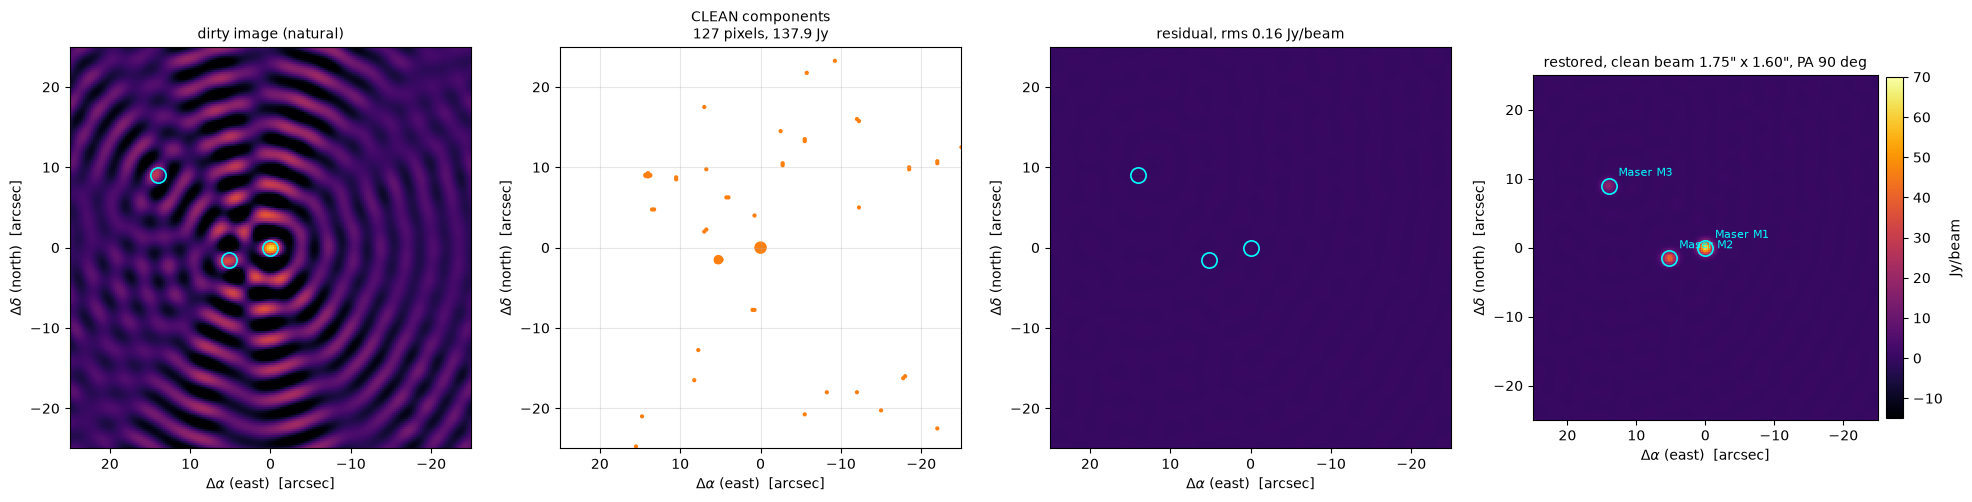

297 iterations, clean beam 1.75" x 1.60", PA 90 deg, residual rms 0.16 Jy/beam
rms error against the truth (within 30"): dirty 8.63, restored 0.19 Jy/beam

source       true  apparent   dirty  restored  CLEAN flux
Maser M1     70.0      67.0    62.0      65.4        65.3
Maser M2     45.0      43.0    33.7      41.0        41.2
Maser M3     20.0      19.1    25.3      17.9        18.0


In [3]:
img, beam = maser_images(target)
cb = CleanBeam.fit(beam)
res = HogbomClean(gain=0.1, niter=5000, threshold_jy=0.45, positive=True).deconvolve(img, beam, cb)
truth = reference_image(masers, img, M1, cb, antenna=dish, freq_hz=OH_1665)
marks = sky_marks(masers, M1)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
plot_image(img, ax=axes[0], zoom_arcsec=25, marks=marks, vmin=-15, vmax=70, colorbar=False, title="dirty image (natural)")
plot_components(res, axes[1], 25)
plot_image(res.residual, ax=axes[2], zoom_arcsec=25, marks=marks, vmin=-15, vmax=70, colorbar=False,
           title=f"residual, rms {res.residual.rms():.2f} Jy/beam")
plot_image(res.restored, ax=axes[3], zoom_arcsec=25, marks=marks, labels=True, vmin=-15, vmax=70,
           title=f"restored, clean beam {cb}")
fig.tight_layout(); plt.show()
print(f"{res.n_iter} iterations, clean beam {cb}, residual rms {res.residual.rms():.2f} Jy/beam")
print(f"rms error against the truth (within 30\"): dirty {rms_error(img, truth, 30):.2f}, "
      f"restored {rms_error(res.restored, truth, 30):.2f} Jy/beam\n")
print(f"{'source':<10s} {'true':>6s} {'apparent':>9s} {'dirty':>7s} {'restored':>9s} {'CLEAN flux':>11s}")
for (name, l, m), c in zip(maser_offsets(), masers):
    print(f"{name:<10s} {c.flux_jy:6.1f} {truth.value_at(l, m):9.1f} {img.value_at(l, m):7.1f} "
          f"{res.restored.value_at(l, m):9.1f} {res.flux_within(l, m, 1.0):11.1f}")

CLEAN removes the mutual sidelobes: the restored values are within a few Jy of the apparent flux densities (dirty: up to 9 Jy off), the rms error drops by a factor of about 40. The remaining deficit (M2: ≈ 41 instead of 43 Jy) comes from the ambiguity of a single baseline: part of the flux is assigned to sidelobe positions, where the fringe pattern of the beam repeats.

## 3. Convergence and loop gain

The residual peak falls roughly geometrically, $(1-g)$ per iteration on a single source; a smaller gain needs proportionally more iterations but treats overlapping sidelobes more carefully. For this field the result hardly depends on $g$ – for complex fields $g$ = 0.05–0.1 is the usual choice.

 gain  iterations  CLEAN flux [Jy]  rms error  residual rms
 0.05         594            137.7       0.20          0.16
 0.10         297            137.9       0.19          0.16
 0.30         103            140.4       0.19          0.15


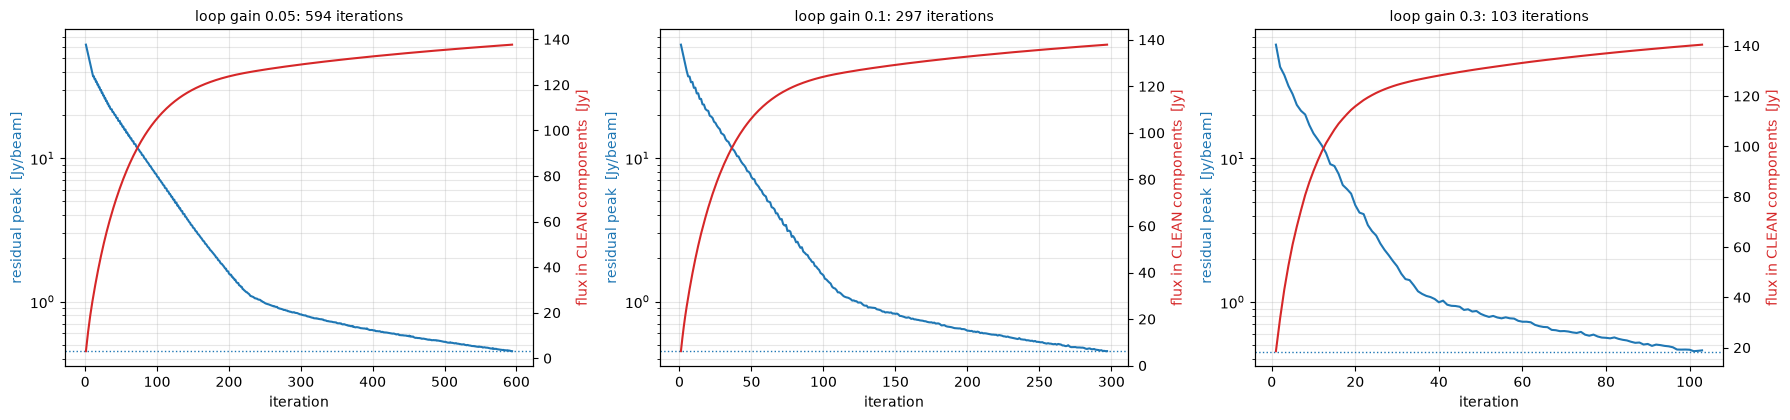

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
print(f"{'gain':>5s} {'iterations':>11s} {'CLEAN flux [Jy]':>16s} {'rms error':>10s} {'residual rms':>13s}")
for ax, g in zip(axes, (0.05, 0.1, 0.3)):
    r = HogbomClean(gain=g, niter=5000, threshold_jy=0.45, positive=True).deconvolve(img, beam, cb)
    plot_clean_history(r, ax=ax, title=f"loop gain {g}: {r.n_iter} iterations")
    print(f"{g:5.2f} {r.n_iter:11d} {r.total_flux_jy:16.1f} {rms_error(r.restored, truth, 30):10.2f} {r.residual.rms():13.2f}")
fig.tight_layout(); plt.show()

## 4. Wiener against CLEAN

As in notebook A, case B: the truth convolved with the clean beam, the dirty image (natural), the Wiener-weighted image (notebook 06, $k = 1$), the Wiener filter applied to the dirty image (to the resolution of the clean beam) and the restored CLEAN image. The Wiener filter keeps only the measured uv cells – here a thin ellipse – and the clean beam transfers a filled disc: most of the flux simply is not there. Only the non-linear CLEAN recovers the masers.

image                     rms error   values at M1 / M2 / M3 [Jy/beam]
truth * clean beam             0.00    67.0 /  43.0 /  19.1
dirty image (natural)          8.63    62.0 /  33.7 /  25.3
Wiener weighting, k = 1        8.41    61.2 /  32.5 /  25.6
Wiener filter, NSR 0.01        1.92     1.3 /   0.7 /   0.6
CLEAN, restored                0.19    65.4 /  41.0 /  17.9


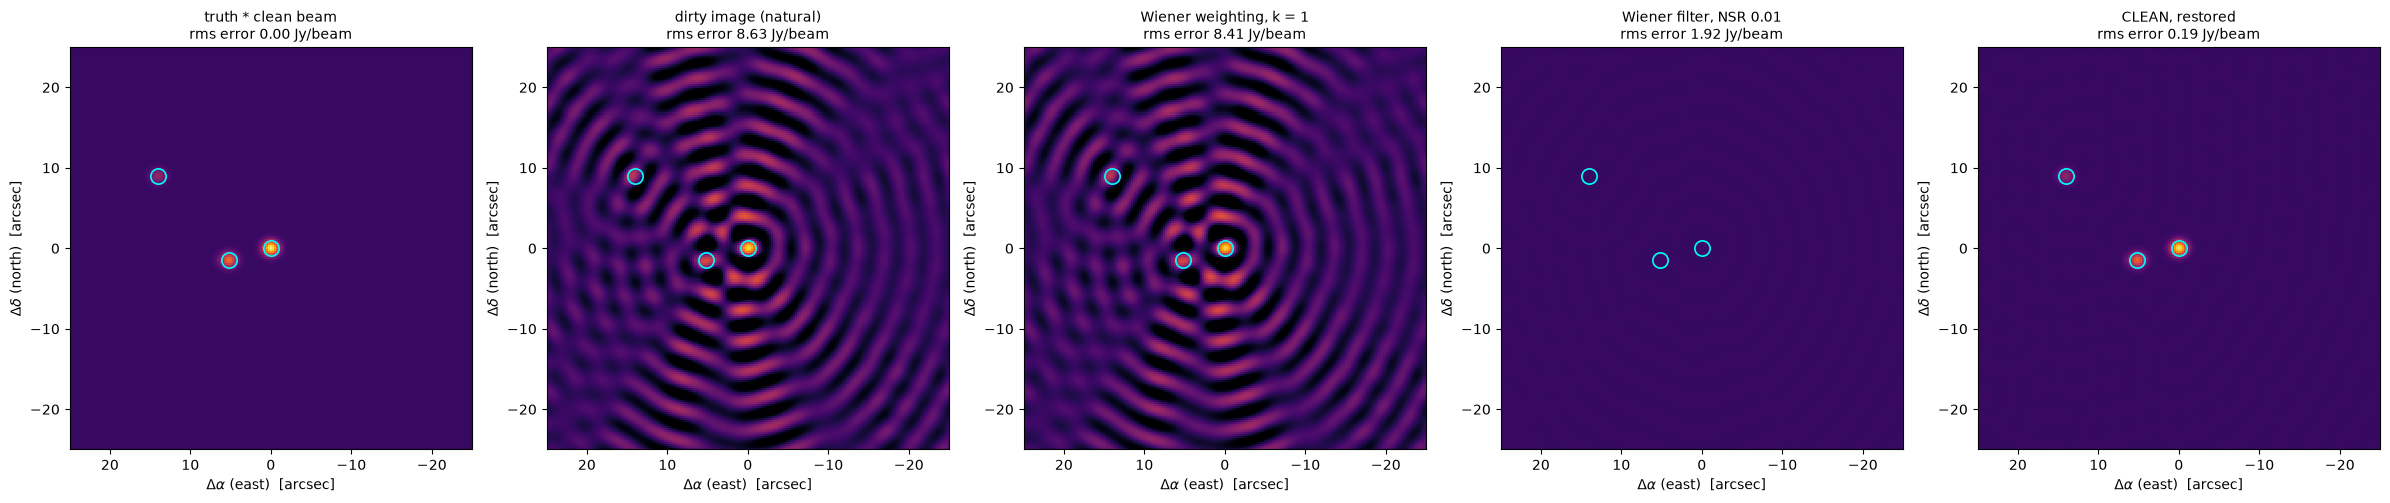

measured uv cells: 292 of 262144 (0.11 %)


In [5]:
img_w, _ = maser_images(target, WienerWeighting(1.0))
wf = WienerFilter(1e-2).apply(img, beam, target=cb)
panels = [(truth, "truth * clean beam"), (img, "dirty image (natural)"),
          (img_w, "Wiener weighting, k = 1"), (wf, "Wiener filter, NSR 0.01"), (res.restored, "CLEAN, restored")]
fig, axes = plt.subplots(1, 5, figsize=(24, 4.8))
print(f"{'image':<24s} {'rms error':>10s}   values at M1 / M2 / M3 [Jy/beam]")
for ax, (im_, ttl) in zip(axes, panels):
    err = rms_error(im_, truth, 30)
    plot_image(im_, ax=ax, zoom_arcsec=25, marks=marks, vmin=-15, vmax=70, colorbar=False,
               title=f"{ttl}\nrms error {err:.2f} Jy/beam")
    vals = " / ".join(f"{im_.value_at(l, m):5.1f}" for _, l, m in maser_offsets())
    print(f"{ttl:<24s} {err:10.2f}   {vals}")
fig.tight_layout(); plt.show()
uv_fill = np.count_nonzero(np.abs(WienerFilter().transfer(beam)) > 1e-6 * np.abs(WienerFilter().transfer(beam)).max())
print(f"measured uv cells: {uv_fill} of {GRID.npix**2} ({100 * uv_fill / GRID.npix**2:.2f} %)")

The small rms error of the Wiener filter is misleading: its image is almost empty (≈ 1 Jy/beam instead of 67 at M1), and an empty map is already closer to a sparse truth than the dirty image with its strong sidelobes. The values at the maser positions show what each method really delivers. With 0.1 % of the uv cells measured, the linear filter can only return that 0.1 %; the Wiener *weighting* changes the beam only slightly (notebook 06).

## 5. More baselines

With the hypothetical third station (6 km north, notebook 06) the beam has sidelobes of only ≈ 0.2: CLEAN has less to disentangle, needs fewer wrong components and recovers the flux densities within about 1 Jy.

project baseline 11.5 km east-west (model) | CLEAN flux per maser (apparent): M1 65.6 (67.0), M2 41.7 (43.0), M3 18.2 (19.1)
hypothetical three-station array | CLEAN flux per maser (apparent): M1 67.2 (67.0), M2 42.4 (43.0), M3 18.6 (19.1)


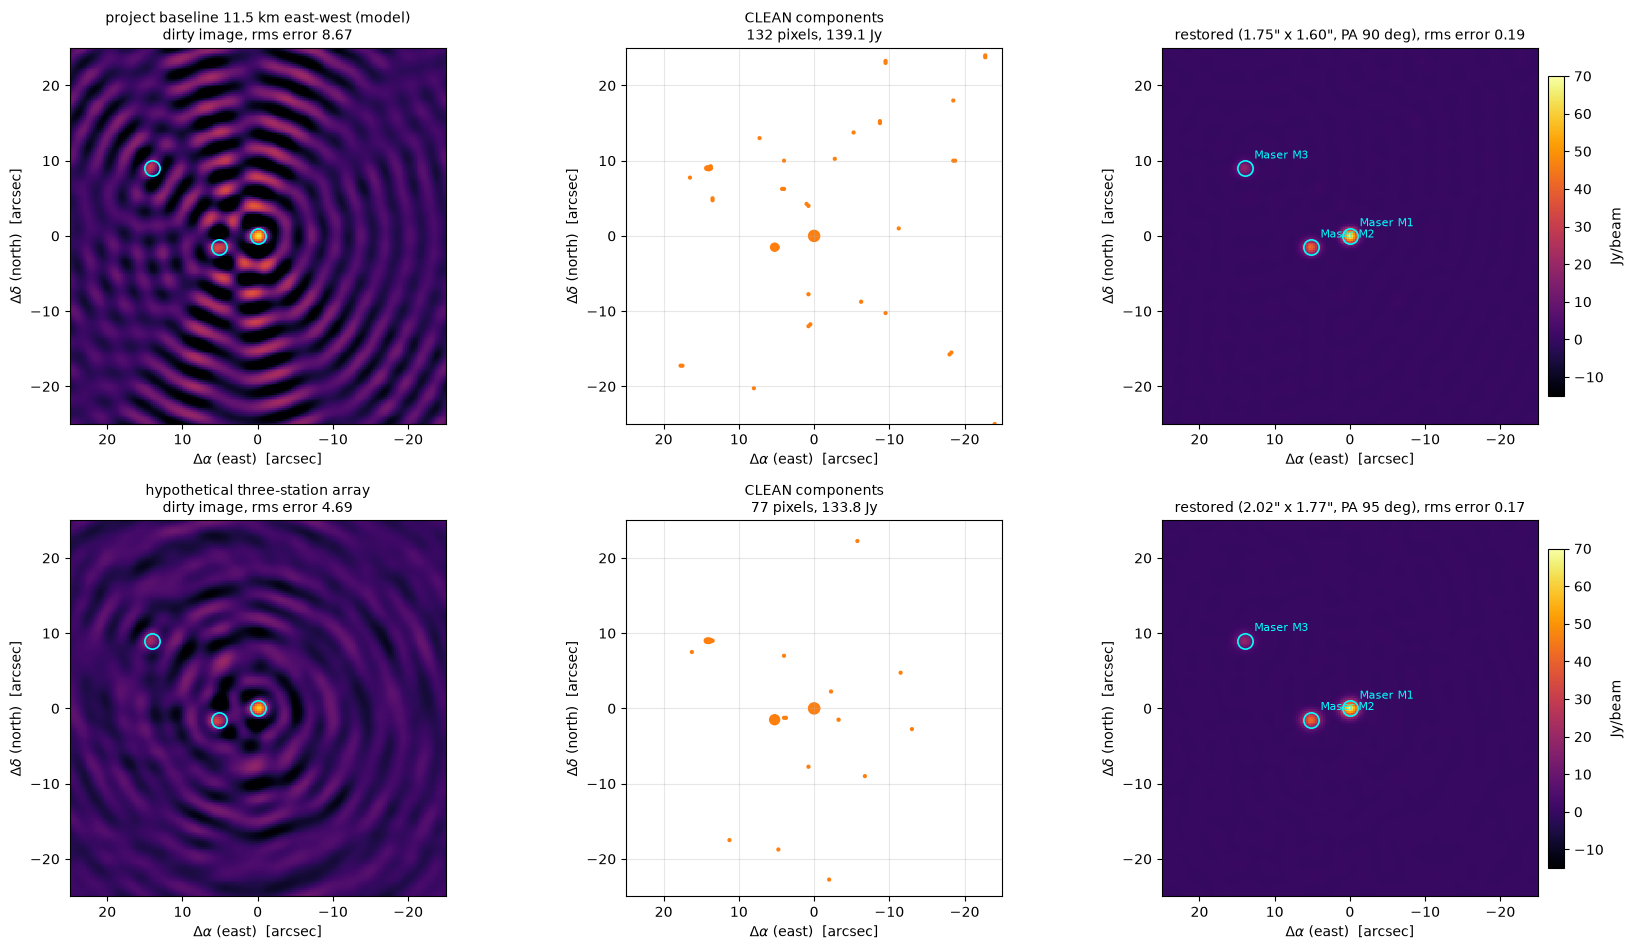

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9.6))
for row, arr in enumerate((target, three)):
    im_a, bm_a = maser_images(arr, seed=2)
    cb_a = CleanBeam.fit(bm_a)
    r = HogbomClean(gain=0.1, niter=5000, threshold_jy=0.45, positive=True).deconvolve(im_a, bm_a, cb_a)
    tr = reference_image(masers, im_a, M1, cb_a, antenna=dish, freq_hz=OH_1665)
    plot_image(im_a, ax=axes[row, 0], zoom_arcsec=25, marks=marks, vmin=-15, vmax=70, colorbar=False,
               title=f"{arr.name}\ndirty image, rms error {rms_error(im_a, tr, 30):.2f}")
    plot_components(r, axes[row, 1], 25)
    plot_image(r.restored, ax=axes[row, 2], zoom_arcsec=25, marks=marks, labels=True, vmin=-15, vmax=70,
               title=f"restored ({cb_a}), rms error {rms_error(r.restored, tr, 30):.2f}")
    print(arr.name, "| CLEAN flux per maser (apparent):",
          ", ".join(f"{n[-2:]} {r.flux_within(l, m, 1.0):.1f} ({tr.value_at(l, m):.1f})" for n, l, m in maser_offsets()))
fig.tight_layout(); plt.show()

## 6. Limits: Cygnus A

CLEAN can only restore what the components can explain from the measured spatial frequencies. Cygnus A at 1420 MHz (uniform weighting, ±8 h, cell 0.5″): the lobes (45″ × 25″, ≈ 1400 Jy) are resolved out on 6–13 km baselines – the visibilities contain almost nothing of them, and CLEAN cannot invent the missing short spacings. Even the hotspots (80 and 75 Jy, FWHM 3″) are partly resolved at 30–60 kλ; CLEAN recovers what is left of them, broken into many components (orange positive, blue negative), many of them along the fringe pattern of the beam. With the single baseline the components scatter positive and negative along the north–south fringe through each hotspot, and the clean beam averages them: the restored peak (≈ 15 Jy/beam) is even lower than the dirty one. The restored image has half the rms error of the dirty image, but the total CLEAN flux is a small fraction of the 1556 Jy of the source. Same colour scale in all panels of a row.

project baseline 11.5 km east-west (model): CLEAN flux 9 Jy of 1556 Jy, rms error dirty 1.8 / restored 0.9 Jy/beam
hypothetical three-station array: CLEAN flux 49 Jy of 1556 Jy, rms error dirty 1.6 / restored 0.9 Jy/beam


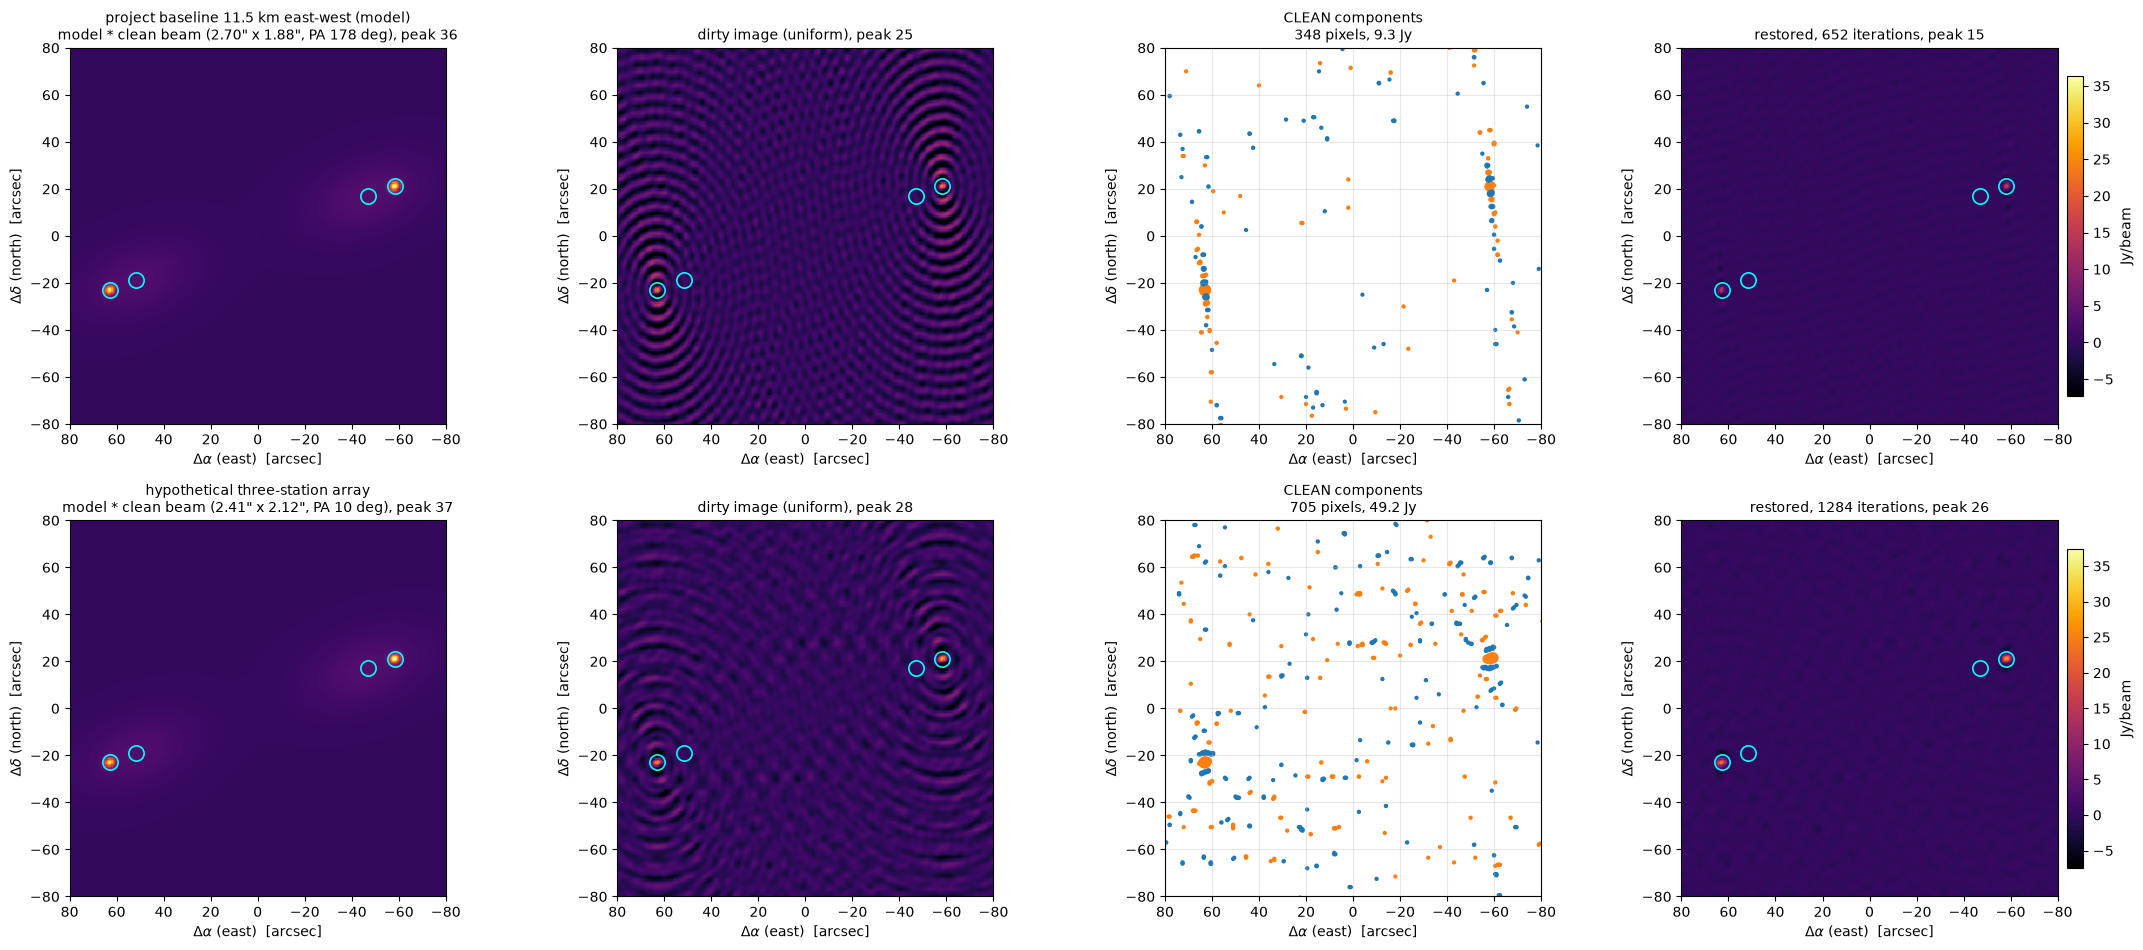

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9.6))
for row, arr in enumerate((target, three)):
    o = Observation.from_sky(cyga, arr, ha_range_h=(-8, 8), t_int_s=120, date=DATE)
    v = VisibilitySimulator(seed=3).run(cyga, o)
    im_c, bm_c = Imager(Gridder(512, 0.5), UniformWeighting()).both(v)
    r = HogbomClean(gain=0.1, niter=3000, frac=0.02).deconvolve(im_c, bm_c)
    tr = reference_image(cyga, im_c, (0.0, 0.0), r.clean_beam, antenna=dish, freq_hz=HI_21CM)
    mk = sky_marks(cyga, min_flux_jy=50)
    vmax = tr.data.max(); vmin = -0.2 * vmax
    plot_image(tr, ax=axes[row, 0], zoom_arcsec=80, marks=mk, vmin=vmin, vmax=vmax, colorbar=False,
               title=f"{arr.name}\nmodel * clean beam ({r.clean_beam}), peak {vmax:.0f}")
    plot_image(im_c, ax=axes[row, 1], zoom_arcsec=80, marks=mk, vmin=vmin, vmax=vmax, colorbar=False,
               title=f"dirty image (uniform), peak {im_c.peak()[0]:.0f}")
    plot_components(r, axes[row, 2], 80)
    plot_image(r.restored, ax=axes[row, 3], zoom_arcsec=80, marks=mk, vmin=vmin, vmax=vmax,
               title=f"restored, {r.n_iter} iterations, peak {r.restored.peak()[0]:.0f}")
    print(f"{arr.name}: CLEAN flux {r.total_flux_jy:.0f} Jy of {cyga.total_flux_jy:.0f} Jy, "
          f"rms error dirty {rms_error(im_c, tr, 60):.1f} / restored {rms_error(r.restored, tr, 60):.1f} Jy/beam")
fig.tight_layout(); plt.show()

For extended emission an interferometer needs short baselines (or a single-dish map combined with the interferometer data); deconvolution methods with other priors (multi-scale CLEAN, maximum entropy) treat extended structure better than point components – possible extensions after 0.9.

## 7. Selector

Source, array, weighting, loop gain, iteration limit, threshold (in Jy/beam), CLEAN window (radius around the image centre, 0 = whole image) and positivity; *Run Interact* shows dirty image, components, residual and restored image with the convergence. (Needs a running kernel.)

In [7]:
import ipywidgets as widgets
from IPython.display import display

SKIES7 = {"w3oh_masers (1665 MHz)": (masers, OH_1665, M1, Gridder(512, 0.25), 25),
          "cyg_a": (cyga, HI_21CM, (0.0, 0.0), Gridder(512, 0.5), 80),
          "vir_a": (SkyModel.from_json(CFG / "skies" / "vir_a.json"), HI_21CM, (0.0, 0.0), Gridder(512, 0.5), 80)}
ARR7 = {"project baseline 11.5 km": target, "three stations (hypothetical)": three,
        "AAS6 stations 11.1 km": Array.from_toml(CFG / "sites" / "aas6_sim_stations.toml")}

def run_clean(source, array_name, weighting, gain, niter, threshold_jy, window_arcsec, positive):
    sky, f, cen, grid, zoom = SKIES7[source]
    o = Observation.from_sky(sky, ARR7[array_name], ha_range_h=(-8, 8), t_int_s=120, freq_hz=f, date=DATE)
    if not o.visible().any():
        print("source below the elevation limit"); return
    v = VisibilitySimulator(seed=4).run(sky, o)
    w = {"natural": NaturalWeighting(), "uniform": UniformWeighting(), "Wiener k=1": WienerWeighting(1.0)}[weighting]
    im_s, bm_s = Imager(grid, w).both(v, center_deg=cen)
    win = [(0.0, 0.0, window_arcsec)] if window_arcsec > 0 else None
    r = HogbomClean(gain=gain, niter=niter, threshold_jy=threshold_jy, positive=positive, window=win).deconvolve(im_s, bm_s)
    tr = reference_image(sky, im_s, cen, r.clean_beam, antenna=ARR7[array_name].stations[0].antenna, freq_hz=f)
    mk = sky_marks(sky, cen, min_flux_jy=10)
    fig, axes = plt.subplots(1, 5, figsize=(25, 4.6))
    vmax = max(tr.data.max(), 1e-3); vmin = -0.2 * vmax
    plot_image(im_s, ax=axes[0], zoom_arcsec=zoom, marks=mk, vmin=vmin, vmax=vmax, colorbar=False, title="dirty image")
    if win:
        axes[0].add_patch(plt.Circle((0, 0), window_arcsec, fill=False, ec="w", ls="--"))
    plot_components(r, axes[1], zoom)
    plot_image(r.residual, ax=axes[2], zoom_arcsec=zoom, vmin=vmin, vmax=vmax, colorbar=False, title="residual")
    plot_image(r.restored, ax=axes[3], zoom_arcsec=zoom, marks=mk, vmin=vmin, vmax=vmax, title=f"restored ({r.clean_beam})")
    if r.n_iter:
        plot_clean_history(r, ax=axes[4])
    fig.tight_layout(); plt.show()
    print(f"{r.n_iter} iterations, CLEAN flux {r.total_flux_jy:.1f} Jy, residual rms {r.residual.rms():.2f} Jy/beam, "
          f"rms error dirty {rms_error(im_s, tr, zoom):.2f} / restored {rms_error(r.restored, tr, zoom):.2f} Jy/beam")

display(widgets.interactive(
    run_clean, {"manual": True},
    source=widgets.Dropdown(options=list(SKIES7), description="source"),
    array_name=widgets.Dropdown(options=list(ARR7), description="array"),
    weighting=widgets.ToggleButtons(options=["natural", "uniform", "Wiener k=1"], description="weighting"),
    gain=widgets.FloatSlider(value=0.1, min=0.01, max=1.0, step=0.01, description="loop gain"),
    niter=widgets.IntSlider(value=2000, min=0, max=10000, step=100, description="n_iter"),
    threshold_jy=widgets.FloatLogSlider(value=0.5, base=10, min=-2, max=2, description="threshold [Jy]"),
    window_arcsec=widgets.FloatSlider(value=0, min=0, max=120, step=1, description="window [\"]"),
    positive=widgets.Checkbox(value=True, description="positive only"),
))

interactive(children=(Dropdown(description='source', options=('w3oh_masers (1665 MHz)', 'cyg_a', 'vir_a'), val…